## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN

# HDBSCAN
try:
    import hdbscan
except ImportError:
    %pip install hdbscan -q
    import hdbscan
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputHDBSCANCosine'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [ ]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


### 1.2 Data Preview

In [3]:
print("5 Baris Pertama Dataset:")
display(df.head())

print("\nNama Semua Kolom:")
print(df.columns.tolist())

5 Baris Pertama Dataset:


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,33554,19.0,Male,France,Teacher,PhD,Employed,NaN,58,Hybrid,...,No,No,Poor,7.0,53.0,26,52,Needs Attention,Reduce Workload,Moderate
1,9428,48.0,Male,Japan,Designer,Bachelor,Employed,NaN,53,Yes,...,Yes,No,Excellent,10.0,54.0,15,42,Needs Attention,Maintain Healthy Routine,Moderate
2,200,42.0,Male,United Kingdom,Police Officer,PhD,Unemployed,NaN,59,No,...,No,No,Average,6.0,50.0,28,46,Needs Attention,Increase Physical Activity,Moderate
3,12448,22.0,Other,Singapore,Lawyer,PhD,Student,NaN,49,Yes,...,No,Yes,Average,5.0,29.0,19,58,Needs Attention,Take Regular Breaks,Moderate
4,39490,62.0,Other,Russia,Doctor,Master,Self-Employed,NaN,39,Yes,...,Yes,No,Poor,1.0,62.0,30,50,Needs Attention,Take Regular Breaks,Moderate



Nama Semua Kolom:
['Person_ID', 'Age', 'Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Remote_Work', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Sleep_Quality', 'Stress_Level', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Exercise_Frequency', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


### 1.3 Tipe Data dan Missing Values

In [4]:
print('Tipe Data:')
print(df.dtypes)

print('\nJumlah Missing Value:')
missing = df.isnull().sum()

missing[missing > 0]

Tipe Data:
Person_ID                          int64
Age                              float64
Gender                               str
Country                              str
Occupation                           str
Education_Level                      str
Employment_Status                    str
Monthly_Income_USD               float64
Work_Hours_Per_Week                int64
Remote_Work                          str
Job_Satisfaction                 float64
Work_Life_Balance                float64
Sleep_Hours                      float64
Sleep_Quality                        str
Stress_Level                         str
Anxiety_Score                    float64
Depression_Score                 float64
Mood_Score                       float64
Emotional_Stability                int64
Physical_Activity_Hours          float64
Exercise_Frequency                   str
Meditation_Minutes               float64
Screen_Time_Hours                float64
Social_Media_Hours               float64
Gamin

Age                          28
Monthly_Income_USD         1450
Job_Satisfaction             37
Work_Life_Balance            60
Sleep_Hours                  85
Anxiety_Score                80
Depression_Score             73
Mood_Score                   91
Physical_Activity_Hours     100
Meditation_Minutes          122
Screen_Time_Hours            84
Social_Media_Hours           62
Gaming_Hours                 69
Therapy_Attendance           43
Life_Satisfaction            75
Productivity_Score           80
dtype: int64

### 1.4 Identifikasi Kolom yang Digunakan

In [5]:
# Kolom numerik asli
numeric_columns = df.select_dtypes(
    include='number'
).columns

# Kolom kategorikal
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal yang akan di-encoding:'
)
print(
    categorical_columns
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal yang akan di-encoding:
Index(['Gender', 'Country', 'Occupation', 'Education_Level',
       'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level',
       'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet',
       'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance',
       'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation',
       'Burnout_Risk'],
      dtype='str')


### 1.5 Statistik Deskriptif

In [6]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Person_ID,5000.0,25098.232600,14310.590082,5.0,12910.75,25300.5,37358.25,49989.0
Age,4972.0,41.684433,13.999166,18.0,29.00,42.0,54.00,65.0
Monthly_Income_USD,3550.0,6282.846197,3331.236477,500.0,3307.25,6370.5,9170.75,11998.0
Work_Hours_Per_Week,5000.0,45.032800,14.636945,20.0,32.00,45.0,58.00,70.0
Job_Satisfaction,4963.0,5.601048,2.876333,1.0,3.00,6.0,8.00,10.0
Work_Life_Balance,4940.0,5.520040,2.896089,1.0,3.00,6.0,8.00,10.0
Sleep_Hours,4915.0,6.956765,1.722117,4.0,5.50,6.9,8.40,10.0
Anxiety_Score,4920.0,40.857520,25.983071,0.0,20.00,40.0,60.00,100.0
Depression_Score,4927.0,41.036736,26.155498,0.0,20.00,40.0,60.00,100.0
Mood_Score,4909.0,59.207374,25.762049,0.0,41.00,59.0,80.00,100.0


### 1.6 Visualisasi Distribusi Data

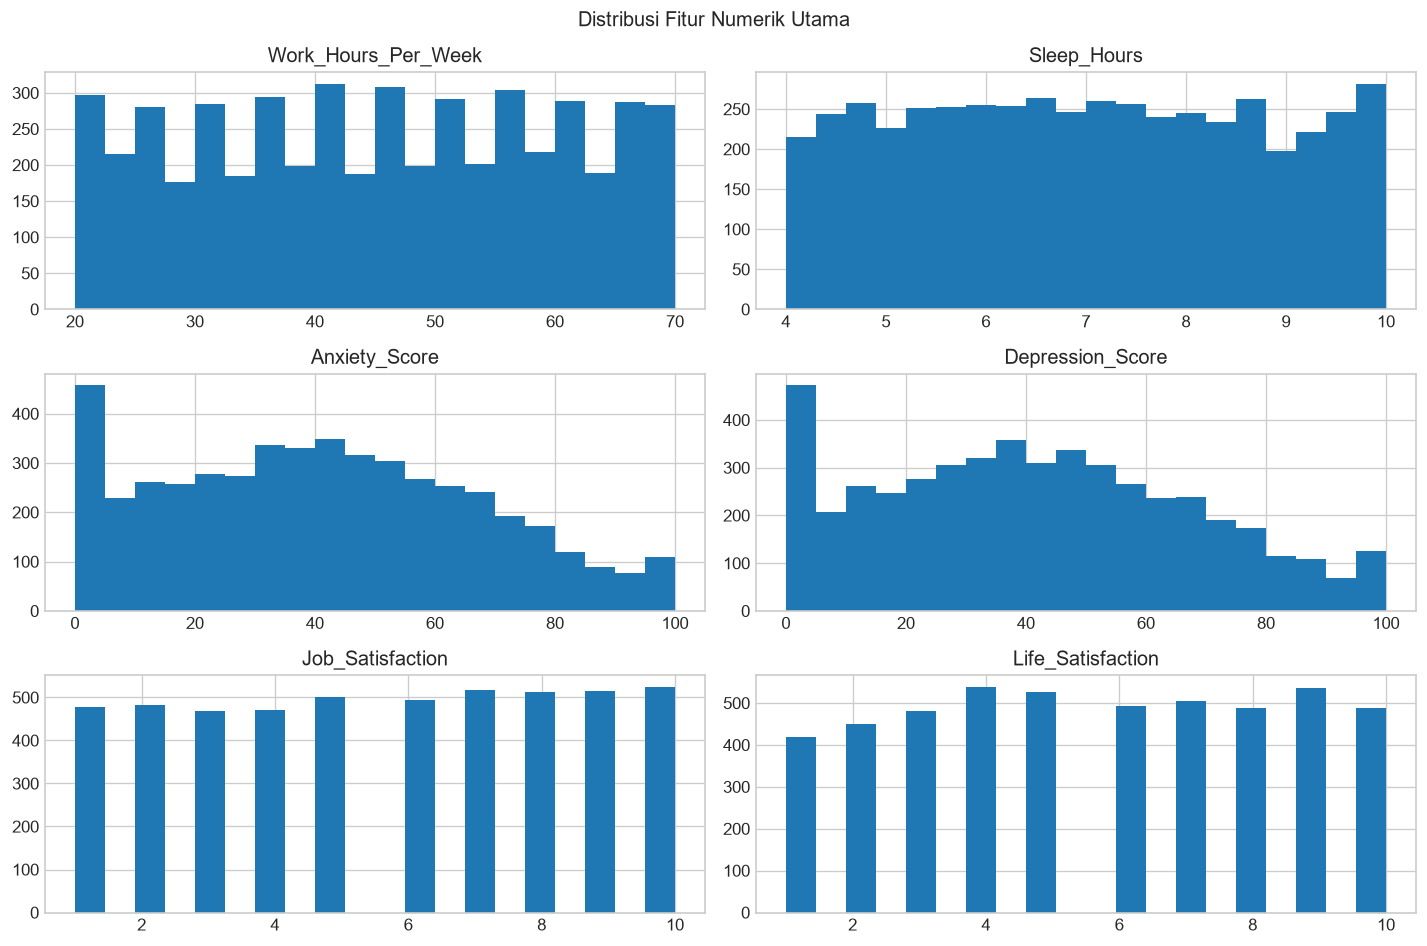

In [7]:
selected_features = [
    'Work_Hours_Per_Week',
    'Sleep_Hours',
    'Anxiety_Score',
    'Depression_Score',
    'Job_Satisfaction',
    'Life_Satisfaction'
]

df[selected_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle('Distribusi Fitur Numerik Utama')
plt.tight_layout()
plt.show()

### 1.7 Visualisasi Deteksi Outlier

In [8]:
numeric_columns = df.select_dtypes(include='number').columns

numeric_columns = numeric_columns.drop(
    ['person_id', 'Person_ID'],
    errors='ignore'
)

numeric_data = df[numeric_columns]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (numeric_data < lower_bound) |
    (numeric_data > upper_bound)
)

In [9]:
outlier_summary = pd.DataFrame({
    'Jumlah Outlier': outlier_mask.sum(),
    'Persentase (%)': (
        outlier_mask.sum() / len(df) * 100
    ).round(2)
})

outlier_summary = outlier_summary.sort_values(
    'Jumlah Outlier',
    ascending=False
)

outlier_summary

,Jumlah Outlier,Persentase (%)
Age,0,0.0
Monthly_Income_USD,0,0.0
Work_Hours_Per_Week,0,0.0
Job_Satisfaction,0,0.0
Work_Life_Balance,0,0.0
Sleep_Hours,0,0.0
Anxiety_Score,0,0.0
Depression_Score,0,0.0
Mood_Score,0,0.0
Emotional_Stability,0,0.0


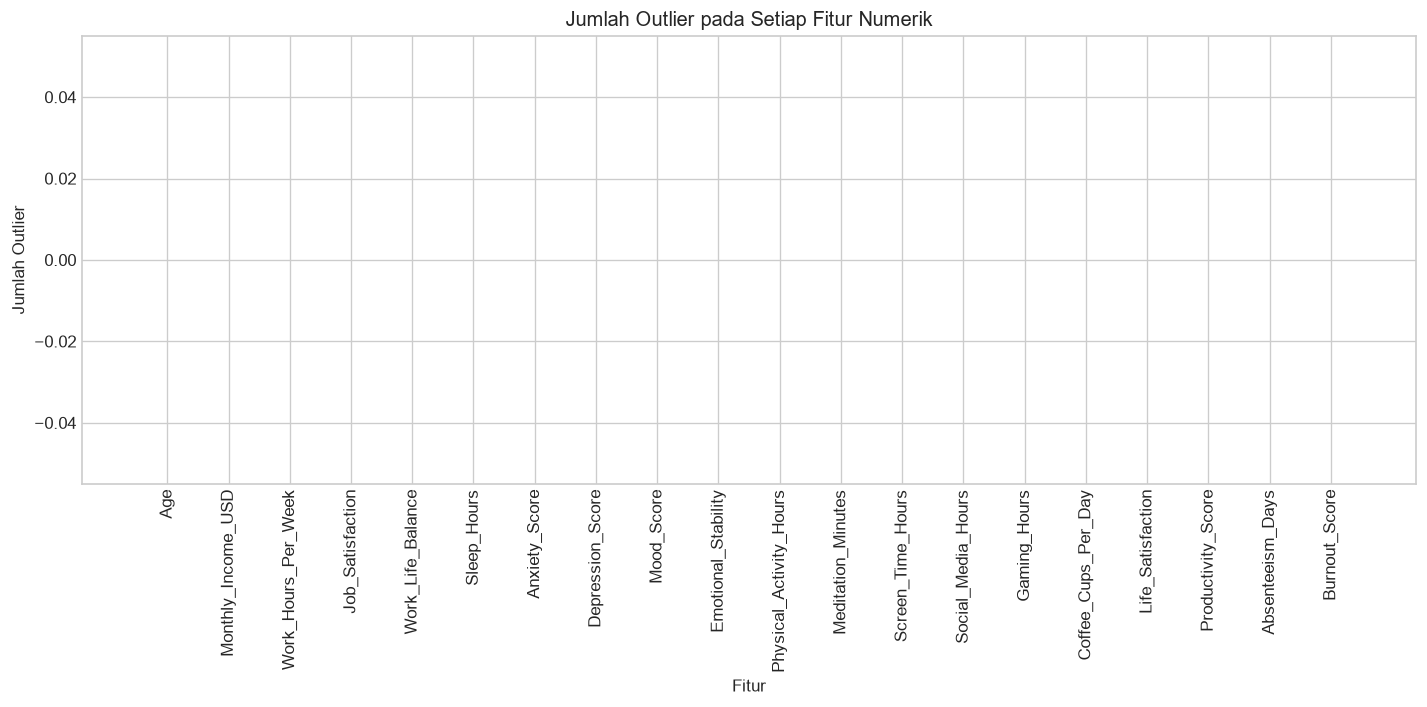

In [10]:
plt.figure(figsize=(12, 6))

plt.bar(
    outlier_summary.index,
    outlier_summary['Jumlah Outlier']
)

plt.title('Jumlah Outlier pada Setiap Fitur Numerik')
plt.xlabel('Fitur')
plt.ylabel('Jumlah Outlier')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## 2. Preprocessing

### 2.1 Seleksi Kolom

In [11]:
# Drop beberapa kolom yang tidak perlu
numeric_columns = numeric_columns.drop(
    ['Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


### 2.2 Encoding Data Kategorikal

In [12]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,1,0,0,1.0,3,1
1,2,3,1,3,0,1,1,0,1,1.0,0,1
2,0,3,1,0,0,1,1,0,0,1.0,2,1
3,2,2,2,3,0,1,0,1,0,0.0,2,1
4,2,3,1,1,0,1,1,0,1,1.0,3,1


### 2.3 Penanganan Missing Values

In [13]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

X = X.fillna(
    X.mean()
)

print(
    '\nJumlah missing value setelah preprocessing:'
)

print(
    X.isnull().sum()
)

Missing value sebelum preprocessing:
Age                                28
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                   37
Work_Life_Balance                  60
Sleep_Hours                        85
Anxiety_Score                      80
Depression_Score                   73
Mood_Score                         91
Emotional_Stability                 0
Physical_Activity_Hours           100
Meditation_Minutes                122
Screen_Time_Hours                  84
Social_Media_Hours                 62
Gaming_Hours                       69
Coffee_Cups_Per_Day                 0
Life_Satisfaction                  75
Productivity_Score                 80
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Penanganan Outlier

Kode sumber tidak melakukan penanganan outlier.

### 2.5 Standardisasi

In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X
)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.000000,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,0.982159,-0.403808,-0.973550,1.014305,1.351177,0.353005
1,0.452453,0.000000,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005
2,0.022608,0.000000,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,0.982159,-0.403808,-0.973550,1.014305,0.453862,0.353005
3,-1.410210,0.000000,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,-1.018165,2.476422,-0.973550,-0.994449,0.453862,0.353005
4,1.455425,0.000000,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,1.351177,0.353005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.667376,0.195668,1.705936,-1.605736,-0.180672,-0.618989,1.518814,2.001572,-1.575281,-1.343280,...,1.811640,-0.472624,1.031702,-0.989654,0.982159,2.476422,-0.973550,1.014305,-0.443453,1.610144
4996,0.452453,-0.044840,-0.617185,-0.907749,0.166747,-0.618989,0.781572,0.345256,-0.282377,-0.959519,...,0.390969,-1.360347,1.031702,1.010455,-1.018165,-0.403808,-0.973550,-0.994449,1.351177,0.353005
4997,-0.837083,-1.379573,1.159320,0.488225,0.861585,-1.497599,2.178451,1.616382,-2.202144,-2.187555,...,1.811640,-0.472624,-0.969272,1.010455,0.982159,2.476422,-0.973550,1.014305,0.453862,1.610144
4998,0.452453,0.110154,1.569282,0.139232,-0.875510,-1.321877,0.083133,0.191180,-0.047304,0.076637,...,0.390969,-1.360347,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005


### 2.6 Data Bersih

In [15]:
print('Dimensi data setelah preprocessing:', X.shape)
print('Jumlah missing value:', X.isnull().sum().sum())

X_scaled.head()

Dimensi data setelah preprocessing: (5000, 31)
Jumlah missing value: 0


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.0,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,0.982159,-0.403808,-0.973550,1.014305,1.351177,0.353005
1,0.452453,0.0,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005
2,0.022608,0.0,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,0.982159,-0.403808,-0.973550,1.014305,0.453862,0.353005
3,-1.410210,0.0,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,-1.018165,2.476422,-0.973550,-0.994449,0.453862,0.353005
4,1.455425,0.0,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,1.351177,0.353005


## 3. Modeling

### 3.1 Inisialisasi Model HDBSCAN Cosine

In [16]:
# Inisialisasi Model HDBSCAN dengan Cosine Distance

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=5,
    metric='cosine',
    algorithm='generic',
    cluster_selection_method='eom'
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [17]:
tracemalloc.start()
t0 = time.perf_counter()

labels = clusterer.fit_predict(X_scaled)

durasi_hdb = time.perf_counter() - t0
_, peak_mem_hdb = tracemalloc.get_traced_memory()
tracemalloc.stop()
peak_mem_hdb_mb = peak_mem_hdb / (1024 * 1024)


### 3.3 Penggabungan Label dengan Data

In [18]:
# Menambahkan label cluster
X_clustered = X_scaled.copy()
X_clustered['Cluster'] = labels

X_clustered.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status,Cluster
0,-1.625133,0.0,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,1.302823,1.031702,-0.989654,0.982159,-0.403808,-0.973550,1.014305,1.351177,0.353005,-1
1,0.452453,0.0,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,1.302823,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005,-1
2,0.022608,0.0,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,-1.360347,-0.969272,1.010455,0.982159,-0.403808,-0.973550,1.014305,0.453862,0.353005,1
3,-1.410210,0.0,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.302823,-0.969272,1.010455,-1.018165,2.476422,-0.973550,-0.994449,0.453862,0.353005,1
4,1.455425,0.0,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,-0.472624,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,1.351177,0.353005,-1


## 4. Evaluasi

### 4.0 Persiapan dan Validasi Data Evaluasi Tanpa Noise

In [19]:
# Noise dikeluarkan dari seluruh evaluasi internal.
mask = labels != -1
X_eval = X_scaled[mask]
labels_eval = labels[mask]

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
noise_percentage = n_noise / len(labels) * 100
n_eval = len(labels_eval)
n_clusters_eval = len(set(labels_eval))
evaluation_valid = 2 <= n_clusters_eval < n_eval

print("Jumlah cluster terbentuk :", n_clusters)
print("Jumlah data noise (-1)   :", n_noise)
print(f"Persentase noise          : {noise_percentage:.2f}%")
print("Jumlah data untuk evaluasi:", n_eval)
if not evaluation_valid:
    print("Evaluasi tidak tersedia: perlu 2 sampai n_samples - 1 klaster non-noise.")

Jumlah cluster terbentuk : 2
Jumlah data noise (-1)   : 2665
Persentase noise          : 53.30%
Jumlah data untuk evaluasi: 2335


Silhouette tetap menggunakan jarak Euclidean seperti kode sumber, walaupun model menggunakan cosine. DBI dan Calinski-Harabasz juga menggunakan geometri Euclidean. Nilai NaN pada tabel berarti evaluasi tidak dapat dihitung, bukan skor nol.

### 4.1 Silhouette Score

In [20]:
silhouette = np.nan
if evaluation_valid:
    silhouette = silhouette_score(X_eval, labels_eval)
print("Silhouette Score (Euclidean):", round(silhouette, 4))

Silhouette Score (Euclidean): 0.3292


### 4.2 Davies-Bouldin Index

In [21]:
db_score = np.nan
if evaluation_valid:
    db_score = davies_bouldin_score(X_eval, labels_eval)
print("Davies-Bouldin Index:", round(db_score, 4))

Davies-Bouldin Index: 1.2777


### 4.3 Calinski-Harabasz Index

In [22]:
ch_score = np.nan
if evaluation_valid:
    ch_score = calinski_harabasz_score(X_eval, labels_eval)
print("Calinski-Harabasz Index:", round(ch_score, 4))

Calinski-Harabasz Index: 1340.8484


### 4.4 Distribusi Anggota Klaster

In [23]:
cluster_distribution = pd.Series(labels).value_counts().sort_index()
distribution = cluster_distribution.rename('Jumlah_Anggota').to_frame()
distribution.index.name = 'Cluster'
display(distribution)

,Jumlah_Anggota
Cluster,
-1,2665
0,1456
1,879


Label `-1` pada distribusi menunjukkan noise dan tidak dihitung sebagai klaster.

### 4.5 Ringkasan Waktu Eksekusi dan Memori

In [24]:
df_runtime = pd.DataFrame([{
    'Metode': 'HDBSCAN',
    'Waktu_Detik': durasi_hdb,
    'Peak_Traced_Memory_MB': peak_mem_hdb_mb
}])
display(df_runtime)

,Metode,Waktu_Detik,Peak_Traced_Memory_MB
0,HDBSCAN,2.720162,476.990909


### 4.6 Ringkasan Evaluasi

In [25]:
evaluation_result = pd.DataFrame({
    'Metric': ['Silhouette Score', 'Davies-Bouldin Score', 'Calinski-Harabasz Score'],
    'Value': [silhouette, db_score, ch_score]
})

df_eval = pd.DataFrame([{
    'Metode': 'HDBSCAN',
    'Metrik_Jarak': 'Cosine',
    'Metrik_Silhouette': 'Euclidean',
    'Min_Cluster_Size': clusterer.min_cluster_size,
    'Min_Samples': clusterer.min_samples,
    'Jumlah_Data': len(labels),
    'Jumlah_Cluster': n_clusters,
    'Jumlah_Noise': n_noise,
    'Persentase_Noise': round(noise_percentage, 2),
    'Jumlah_Data_Evaluasi': n_eval,
    'Evaluasi_Valid': evaluation_valid,
    'Waktu_Detik': round(durasi_hdb, 4),
    'Peak_Memory_MB': round(peak_mem_hdb_mb, 2),
    'Silhouette': round(silhouette, 4),
    'DBI': round(db_score, 4),
    'Calinski_Harabasz': round(ch_score, 4)
}])
display(df_eval)

,Metode,Metrik_Jarak,Metrik_Silhouette,Min_Cluster_Size,Min_Samples,Jumlah_Data,Jumlah_Cluster,Jumlah_Noise,Persentase_Noise,Jumlah_Data_Evaluasi,Evaluasi_Valid,Waktu_Detik,Peak_Memory_MB,Silhouette,DBI,Calinski_Harabasz
0,HDBSCAN,Cosine,Euclidean,15,5,5000,2,2665,53.3,2335,True,2.7202,476.99,0.3292,1.2777,1340.8484


## 5. Visualisasi Hasil

### 5.1 Reduksi Dimensi PCA

In [26]:
# PCA untuk Visualisasi 2 Dimensi

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PCA1','PCA2']
)

pca_df['Cluster'] = labels

print(
    "Total variance PCA:",
    round(sum(pca.explained_variance_ratio_),4)
)

pca_df.head()

Total variance PCA: 0.3074


,PCA1,PCA2,Cluster
0,-0.450289,2.282250,-1
1,-0.608291,-1.771812,-1
2,-1.347370,-1.712307,1
3,-3.662303,-0.145777,1
4,-0.350715,-2.054289,-1


### 5.2 Visualisasi Klaster dan Noise

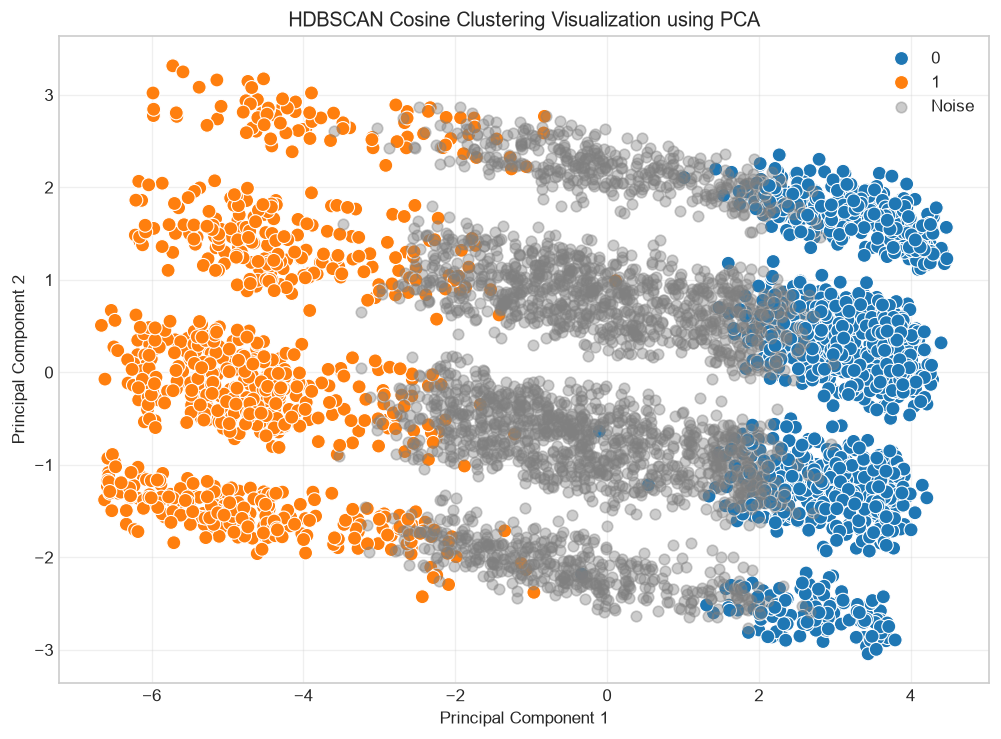

In [27]:
# Visualisasi HDBSCAN Cosine

plt.figure(figsize=(10,7))

# Cluster normal
sns.scatterplot(
    data=pca_df[pca_df['Cluster'] != -1],
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    s=70
)

# Noise
noise = pca_df[pca_df['Cluster'] == -1]

plt.scatter(
    noise['PCA1'],
    noise['PCA2'],
    c='gray',
    alpha=0.4,
    s=40,
    label='Noise'
)

plt.title(
    'HDBSCAN Cosine Clustering Visualization using PCA'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(f'{OUTPUT_DIR}/pca_hdbscan_cosine.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Analisis

### 6.1 Profil Karakteristik Setiap Klaster

In [28]:
# Profil karakteristik setiap cluster

cluster_profile = (
    X_clustered
    .groupby('Cluster')
    .mean()
)

cluster_profile

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
Cluster,,,,,,,,,,,,,,,,,,,,,
-1,-0.012117,-0.012484,0.133952,-0.010839,0.016720,-0.053559,0.140576,0.129486,-0.145021,-0.141048,...,0.044464,0.001717,-0.007453,0.004021,-0.034891,-0.403808,0.000909,0.004186,-0.006075,-0.004089
0,0.010410,0.014084,-0.832631,-0.008801,-0.022634,0.331363,-1.136037,-1.105854,1.143201,1.129714,...,-1.025799,0.002332,0.018847,-0.011579,0.013596,-0.403808,0.000701,-0.016367,0.015681,-0.901544
1,0.019493,0.014519,0.973072,0.047441,-0.013199,-0.386496,1.455556,1.439185,-1.453949,-1.443652,...,1.564356,-0.009069,-0.008622,0.006987,0.083265,1.893167,-0.003918,0.014420,-0.007556,1.505740


Profil menggunakan fitur yang sudah distandardisasi; nilai tersebut bukan satuan asli. Baris `-1`, jika ada, merupakan profil noise.

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [29]:
df_eval.to_csv(f'{OUTPUT_DIR}/metrics_hdbscan_cosine.csv', index=False)
print('Ringkasan evaluasi berhasil disimpan.')

Ringkasan evaluasi berhasil disimpan.


### 7.2 Ekspor Label Klaster

In [30]:
df_labels = pd.DataFrame({'HDBSCAN_Cluster': labels}, index=X_scaled.index)
df_labels.to_csv(f'{OUTPUT_DIR}/labels_hdbscan_cosine.csv', index=False)
print('Label klaster berhasil disimpan.')

Label klaster berhasil disimpan.


### 7.3 Ekspor Distribusi dan Profil Klaster

In [31]:
distribution.to_csv(f'{OUTPUT_DIR}/distribution_hdbscan_cosine.csv')
cluster_profile.to_csv(f'{OUTPUT_DIR}/profile_hdbscan_cosine.csv')
print(f'Hasil disimpan di folder: {OUTPUT_DIR}')

Hasil disimpan di folder: outputHDBSCANCosine
